# vulngraph-gnn: CVE Severity Analysis and Prediction on the Unified Cybersecurity Knowledge Graph

**CS 4330 – Data Science · Fall 2026 · Angelo State University · Dr. Dogdu**

| Team member | Email | Major |
|---|---|---|
| Eryna Plong | rplong@angelo.edu | Computer Science |
| Bunlong Tan | btan@angelo.edu | Computer Science |
| Tanner Love | tlove10@angelo.edu | Artificial Intelligence |

**Repo:** <https://github.com/minty-exit/vulngraph-gnn>

### Project Description

New vulnerabilities (CVEs) are published every day, but the National Vulnerability Database (NVD) often takes weeks or months to assign a severity score. This project combines NVD CVE records with the Unified Cybersecurity Knowledge Graph (UCKG), which links each CVE to its weaknesses (CWE), affected products (CPE) and attack patterns (CAPEC, ATT&CK). We study what drives severity, predict it, and test whether the graph's links improve those predictions, so analysts can prioritize new CVEs before an official score exists.

### Dataset

| Source | URL | Size |
|---|---|---|
| NVD CVE records (NIST) | <https://nvd.nist.gov/developers/vulnerabilities> | 408,816 CVEs (1988–2026), 28 columns; 307,239 have a CVSS v3 severity |
| UCKG (Angelo State University) | <https://doi.org/10.1007/978-3-031-67871-4_2> | 969 CWEs, 559 CAPEC patterns, 921 ATT&CK techniques; 348,049 CVE–CWE and 762,734 CVE–CPE links |

**Schema:**
- **nvd_cves.csv** (one row per CVE): cve_id, published, description, base_score (0–10), severity (LOW, MEDIUM, HIGH, CRITICAL), the 8 CVSS v3 metrics (attack_vector to availability_impact), exploitability_score, impact_score, cwe, vendors, products, plus CVSS v2 and v4 scores.
- **uckg/ nodes:** cwes (cwe_id, name, abstraction, likelihood_of_exploit), capecs (capec_id, name, severity, likelihood), attack_techniques (attack_id, name, domain).
- **uckg/ edges:** edges_cve_cwe, edges_cve_cpe, edges_capec_cwe, edges_capec_attack (pairs of IDs).

### Project Goals

1. Explore the distribution and completeness of CVE severity and CVSS metrics.
2. Identify the features that drive high severity.
3. Predict the CVSS base score from its sub-scores.
4. Group CVEs by description and attributes, and compare the groups with their CWE.
5. Predict a new CVE's severity level before it is scored (Random Forest, XGBoost, GCN), and test whether the graph's links help.

---

## Progress Report 5: Decision Trees and Ensemble Learning

### Setup

**Libraries and data folder:** the first cell imports the libraries and finds the data folder. On Colab it uses the shared Google Drive folder, and when run locally it uses ../dataset.

In [1]:
#==============================================================
#=========== DO NOT MODIFY THIS CODE CELL =====================
#==============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob, pandas as pd
import seaborn as sns

from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

try:
    # Colab: read the data from the shared Google Drive folder
    from google.colab import drive
    drive.mount('/content/drive')
    DATA = (glob.glob('/content/drive/*/vulngraph-gnn/dataset') + glob.glob('/content/drive/*/*/vulngraph-gnn/dataset'))[0]
except ImportError:
    # Local: the dataset folder sits next to this notebook's folder in the repo
    DATA = '../dataset'

U = f'{DATA}/uckg' # U for UCKG
print('Using', DATA)


Using ../dataset


**Loading the data:** the next cell reads the NVD table (one row per CVE) and the knowledge graph's node and edge tables from the uckg folder.

In [2]:
#==============================================================
#=========== DO NOT MODIFY THIS CODE CELL =====================
#==============================================================

# --- Main table: one row per CVE (label = severity or base_score) # parse_dates=['published', 'last_modified'] converts to real dates ---
nvd = pd.read_csv(f'{DATA}/nvd_cves.csv', parse_dates=['published', 'last_modified'], low_memory=False)

# --- Graph nodes ---
cwes   = pd.read_csv(f'{U}/cwes.csv')
capecs = pd.read_csv(f'{U}/capecs.csv')
attack = pd.read_csv(f'{U}/attack_techniques.csv')

# --- Graph edges ---
cve_cwe      = pd.read_csv(f'{U}/edges_cve_cwe.csv')
cve_cpe      = pd.read_csv(f'{U}/edges_cve_cpe.csv')
capec_cwe    = pd.read_csv(f'{U}/edges_capec_cwe.csv')
capec_attack = pd.read_csv(f'{U}/edges_capec_attack.csv')


**Building df:** the next cell combines the NVD table with four counts from the knowledge graph into one table, df. The steps are explained after the cell.

In [3]:
# --- Combined CVE-level table: NVD + graph counts ---
cve_capec  = cve_cwe.merge(capec_cwe, on='cwe_id')[['cve_id', 'capec_id']].drop_duplicates()
cve_attack = cve_capec.merge(capec_attack, on='capec_id')[['cve_id', 'attack_id']].drop_duplicates()

graph_feats = pd.DataFrame({
    'n_cwe':    cve_cwe.groupby('cve_id').size(),
    'n_cpe':    cve_cpe.groupby('cve_id').size(),
    'n_capec':  cve_capec.groupby('cve_id').size(),
    'n_attack': cve_attack.groupby('cve_id').size(),
})

df = nvd.merge(graph_feats, left_on='cve_id', right_index=True, how='left')
df[graph_feats.columns] = df[graph_feats.columns].fillna(0).astype(int)

# Keep only CVEs that have a v3 label
df = df[df['severity'].notna() & (df['severity'] != 'NONE')]


**What the cell does:**
1. `cve_capec` links each CVE to the CAPEC attack patterns of its CWEs, and `cve_attack` follows those patterns on to ATT&CK techniques.
2. `graph_feats` counts, for each CVE, its linked CWEs (**n_cwe**), affected products (**n_cpe**), CAPEC patterns (**n_capec**) and ATT&CK techniques (**n_attack**).
3. The counts are joined onto the NVD table. CVEs with no links in the graph get 0.
4. CVEs without a CVSS v3 severity are dropped, because every model below needs that label.

"df" is the main table for modeling. It has one row per CVE: all the NVD columns plus the four counts taken from the knowledge graph.

In [4]:
# df is the main data frame and can be seen below
print(f'\n=== df  {df.shape} ===')
display(df.head())



=== df  (307239, 32) ===


,cve_id,published,last_modified,vuln_status,description,cvss3_version,cvss3_source,base_score,severity,vector_string,...,cvss4_base_score,cvss4_severity,cwe,all_cwes,vendors,products,n_cwe,n_cpe,n_capec,n_attack
6,CVE-1999-0084,1990-05-01 04:00:00,2026-06-16 21:47:32.553,Modified,Certain NFS servers allow users to use mknod t...,3.1,Secondary,8.4,HIGH,CVSS:3.1/AV:L/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-269,CWE-269,sun,sun:nfs,1,1,3,1
92,CVE-1999-0066,1995-07-31 04:00:00,2026-06-16 21:47:29.853,Modified,AnyForm CGI remote execution.,3.1,Secondary,9.8,CRITICAL,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,NaN,NaN,john_s._roberts,john_s._roberts:anyform,0,1,0,0
130,CVE-1999-0022,1996-07-03 04:00:00,2026-06-16 21:47:22.167,Modified,Local user gains root privileges via buffer ov...,3.1,Secondary,7.8,HIGH,CVSS:3.1/AV:L/AC:L/PR:L/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-125,CWE-125,bsdi;freebsd;hp;ibm;sgi;sun,bsdi:bsd_os;freebsd:freebsd;hp:hp-ux;ibm:aix;s...,1,2,1,0
171,CVE-1999-0043,1996-12-04 05:00:00,2026-06-16 21:47:26.437,Modified,Command execution via shell metachars in INN d...,3.1,Secondary,9.8,CRITICAL,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:H/A:H,...,NaN,NaN,CWE-78,CWE-78,bsdi;caldera;isc;nec;netscape;redhat,bsdi:bsd_os;caldera:openlinux;isc:inn;nec:goah...,1,3,5,0
197,CVE-1999-0236,1997-01-01 05:00:00,2026-06-16 21:47:58.393,Modified,ScriptAlias directory in NCSA and Apache httpd...,3.1,Primary,7.5,HIGH,CVSS:3.1/AV:N/AC:L/PR:N/UI:N/S:U/C:H/I:N/A:N,...,NaN,NaN,NaN,NaN,apache;illinois,apache:http_server;illinois:ncsa_httpd,0,1,0,0


### Task 1: Decision Tree Regression

We train a Decision Tree Regressor to predict the CVSS **base_score** from six attributes: the two CVSS sub-scores (**exploitability_score**, **impact_score**) and the four graph counts (**n_cwe**, **n_cpe**, **n_capec**, **n_attack**). A decision tree predicts by asking a series of yes/no questions about the attributes, so unlike linear regression it can follow non-linear patterns.

**Choosing the attributes and splitting the data:** X holds the six attributes and y holds base_score. We use the same 80/20 split and random_state=42 as the earlier reports, so the results can be compared.

In [5]:
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

features_dt = ['exploitability_score', 'impact_score', 'n_cwe', 'n_cpe', 'n_capec', 'n_attack']
X_dt = df[features_dt]
y_dt = df['base_score']

X_train_dt, X_test_dt, y_train_dt, y_test_dt = train_test_split(X_dt, y_dt, test_size=0.2, random_state=42)

print("Training rows:", len(X_train_dt))
print("Testing rows: ", len(X_test_dt))
print("Attributes:   ", len(features_dt))

Training rows: 245791
Testing rows:  61448
Attributes:    6


The tree learns from 245,791 CVEs (80%) and is tested on 61,448 CVEs (20%), using 6 attributes.

**Training a first tree:** we start with max_depth=5, which lets the tree ask at most 5 questions in a row before it makes a prediction. We measure R², RMSE, and MAE on both the training and the test set. If the training score is much better than the test score, the tree is memorizing instead of learning (overfitting).

In [6]:
tree = DecisionTreeRegressor(max_depth=5, random_state=42)
tree.fit(X_train_dt, y_train_dt)

y_pred_train_dt = tree.predict(X_train_dt)
y_pred_dt = tree.predict(X_test_dt)

print("--- Decision Tree Regressor (max_depth=5) ---")
print(f"Train R²: {r2_score(y_train_dt, y_pred_train_dt):.4f}")
print(f"Test R²:  {r2_score(y_test_dt, y_pred_dt):.4f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test_dt, y_pred_dt)):.4f}")
print(f"Test MAE:  {mean_absolute_error(y_test_dt, y_pred_dt):.4f}")

--- Decision Tree Regressor (max_depth=5) ---
Train R²: 0.9826
Test R²:  0.9822
Test RMSE: 0.2257
Test MAE:  0.1139


With max_depth=5, the tree explains 98.2% of the variation in base_score on the test set (R² 0.9822), and its predictions are off by about 0.23 points (RMSE) or 0.11 points on average (MAE). The training R² (0.9826) is almost the same, so the tree is not overfitting. The error that remains comes from the depth limit: a tree with 5 levels can give at most 2⁵ = 32 different predictions.

**Visualizing the tree and the feature importances:** we draw the top 3 levels of the tree to see which questions it asks first (all 5 levels would be too small to read). Feature importance measures how much each attribute reduces the error across all of the tree's splits, and the six importances add up to 1.

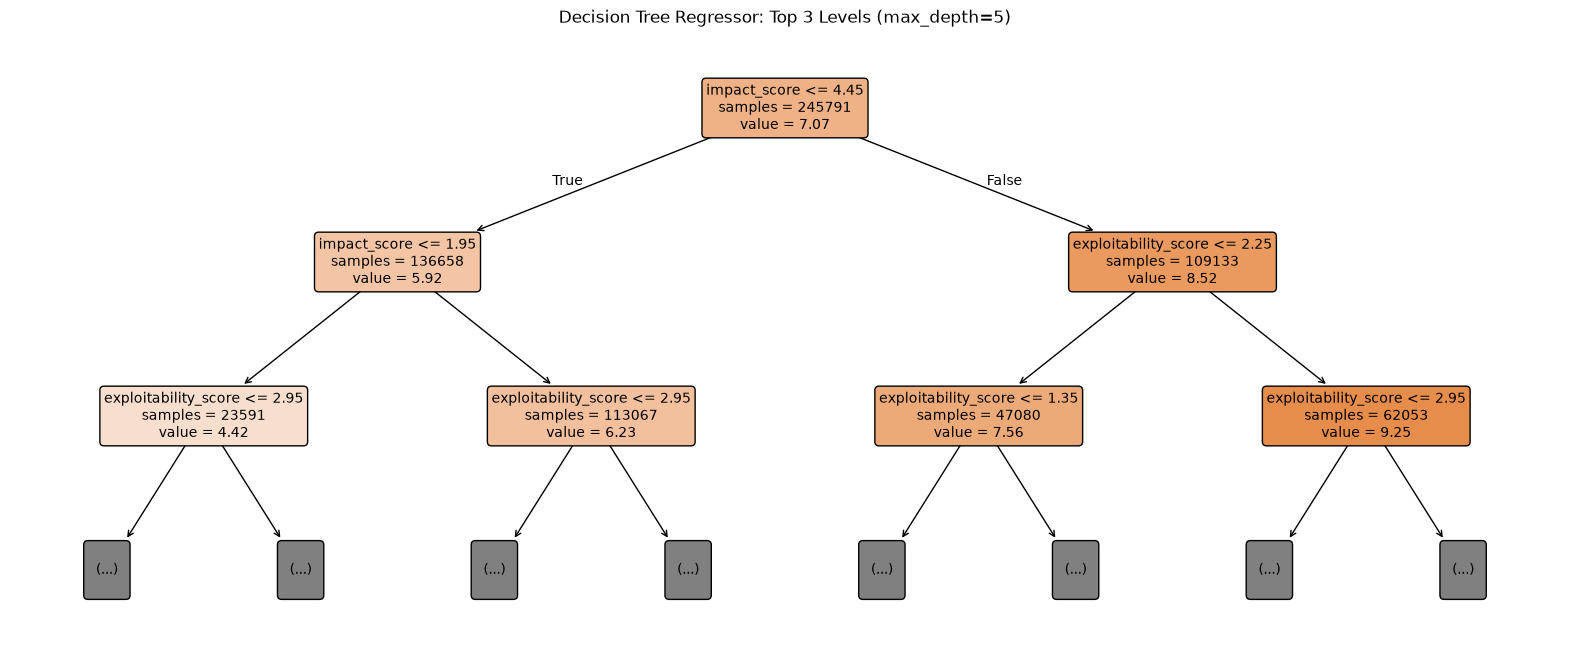

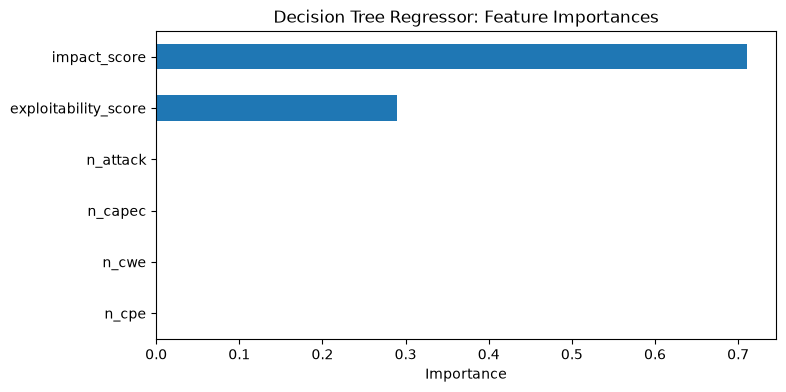

impact_score            0.7102
exploitability_score    0.2898
n_attack                0.0000
n_cpe                   0.0000
n_cwe                   0.0000
n_capec                 0.0000
dtype: float64


In [7]:
# Top 3 levels of the tree
plt.figure(figsize=(20, 8))
plot_tree(tree, max_depth=2, feature_names=features_dt, filled=True, rounded=True,
          fontsize=10, impurity=False, precision=2)
plt.title("Decision Tree Regressor: Top 3 Levels (max_depth=5)")
plt.show()

# Feature importances
importances = pd.Series(tree.feature_importances_, index=features_dt).sort_values()
plt.figure(figsize=(8, 4))
importances.plot(kind='barh')
plt.title("Decision Tree Regressor: Feature Importances")
plt.xlabel("Importance")
plt.show()

print(importances.sort_values(ascending=False).round(4))

The tree's first question is whether impact_score is at most 4.45. CVEs below that average a base score of 5.92 and those above average 8.52. The next questions split on impact_score again on the left and on exploitability_score on the right, and CVEs with high impact and high exploitability end up at an average of 9.25.

impact_score has an importance of 0.71 and exploitability_score 0.29, and the four graph counts have 0. The tree never splits on n_cwe, n_cpe, n_capec, or n_attack, which matches their near-zero correlation with base_score in Progress Report 1. This makes sense because the CVSS formula calculates base_score from the impact and exploitability sub-scores.

**Hyperparameter tuning (max_depth):** we train trees with different maximum depths and compare training and test R² and RMSE. A tree that is too shallow cannot capture the pattern (underfitting). A tree that is too deep can memorize the training data (overfitting), which shows up as a training score that is clearly better than the test score. max_depth=None means no limit.

,leaves,train R²,test R²,test RMSE
max_depth,,,,
2,4,0.7835,0.7838,0.7867
3,8,0.9171,0.9163,0.4895
5,31,0.9826,0.9822,0.2257
8,208,0.9985,0.9985,0.0657
10,577,0.9996,0.9995,0.0379
15,2169,0.9997,0.9996,0.0333
20,3148,0.9997,0.9996,0.0336
None,3302,0.9998,0.9996,0.0335


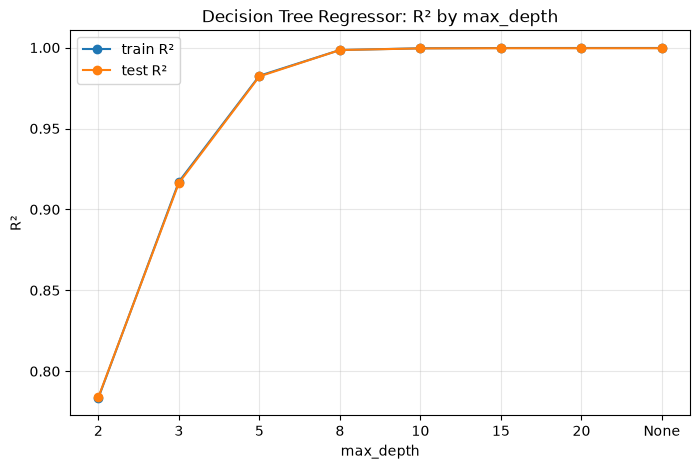

In [8]:
depths = [2, 3, 5, 8, 10, 15, 20, None]
rows = []

for d in depths:
    t = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train_dt, y_train_dt)
    rows.append({
        'max_depth': 'None' if d is None else d,
        'leaves': t.get_n_leaves(),
        'train R²': r2_score(y_train_dt, t.predict(X_train_dt)),
        'test R²': r2_score(y_test_dt, t.predict(X_test_dt)),
        'test RMSE': np.sqrt(mean_squared_error(y_test_dt, t.predict(X_test_dt))),
    })

depth_results = pd.DataFrame(rows).set_index('max_depth')
display(depth_results.round(4))

# Training vs. test R² for each depth
depth_results[['train R²', 'test R²']].plot(marker='o', figsize=(8, 5))
plt.title("Decision Tree Regressor: R² by max_depth")
plt.xlabel("max_depth")
plt.ylabel("R²")
plt.grid(alpha=0.3)
plt.show()

Shallow trees underfit: with max_depth=2 the tree has only 4 leaves and a test R² of 0.78. The test R² rises quickly to 0.9985 at depth 8 and 0.9995 at depth 10 (RMSE 0.038), then stays almost flat. Depth 15 is only slightly better (RMSE 0.033), and depth 20 and no limit are slightly worse again.

The training and test R² stay within 0.0002 of each other at every depth, so even the unlimited tree does not overfit. This is because impact_score and exploitability_score take only a limited set of values: the unlimited tree has 3,310 leaves, about 74 training CVEs per leaf on average, so it cannot memorize individual CVEs. We choose max_depth=10, because it scores almost the same as the deeper trees with 583 leaves instead of 2,221 to 3,310, making it simpler and easier to interpret.

**Final model:** we train the tree with max_depth=10 and report its test R², RMSE, and MAE.

In [9]:
best_tree = DecisionTreeRegressor(max_depth=10, random_state=42)
best_tree.fit(X_train_dt, y_train_dt)
y_pred_best = best_tree.predict(X_test_dt)

r2_dt = r2_score(y_test_dt, y_pred_best)
rmse_dt = np.sqrt(mean_squared_error(y_test_dt, y_pred_best))
mae_dt = mean_absolute_error(y_test_dt, y_pred_best)

print("--- Final Decision Tree Regressor (max_depth=10) ---")
print(f"Test R²:   {r2_dt:.4f}")
print(f"Test RMSE: {rmse_dt:.4f}")
print(f"Test MAE:  {mae_dt:.4f}")
print("Leaves:   ", best_tree.get_n_leaves())

--- Final Decision Tree Regressor (max_depth=10) ---
Test R²:   0.9995
Test RMSE: 0.0379
Test MAE:  0.0072
Leaves:    577


#### Report:

| Model | Attributes | Test R² | Test RMSE | Test MAE |
|---|---|---|---|---|
| Linear regression (Progress Report 3, Task 1) | impact_score | 0.7094 | 0.9122 | 0.7666 |
| Multiple linear regression (Progress Report 3, Task 2) | exploitability_score, impact_score, n_cpe | 0.9865 | 0.1968 | 0.1404 |
| Decision tree, max_depth=5 | 6 attributes | 0.9822 | 0.2257 | 0.1139 |
| **Decision tree, max_depth=10** | **6 attributes** | **0.9995** | **0.0379** | **0.0072** |

The final decision tree (max_depth=10, 583 leaves) explains 99.95% of the variation in base_score. Its MAE of 0.007 is about five times smaller than its RMSE of 0.038, which means almost every CVE is predicted nearly exactly and the remaining error comes from a small number of CVEs that are further off. It cuts the RMSE of the multiple linear regression by about 80%, because the CVSS formula is not a straight line (it multiplies, caps, and rounds), and a tree can follow those steps while a linear model cannot.

**Takeaway:** the tree only uses impact_score (importance 0.71) and exploitability_score (0.29). The four graph counts are almost never used (importance 0.0001 or less), so the knowledge graph counts add nothing once the two CVSS sub-scores are known. Tuning max_depth showed underfitting below depth 8 and no overfitting at any depth, because the two sub-scores take a limited set of values. This model mainly rediscovers the CVSS formula, so predicting severity before a CVE has been scored (without its sub-scores) remains the harder problem for later tasks.

### Task 2: Decision Tree Classification

We train a Decision Tree Classifier to predict the four severity levels (LOW, MEDIUM, HIGH, CRITICAL). Severity is just base_score cut into bands, so with the two sub-scores from Task 1 the tree would be almost perfect again. Instead, we only use information that is known before a CVE is scored: the four graph counts and the CVE's CWE (weakness type).

**Choosing the attributes and splitting the data:** X holds the four graph counts plus the 20 most common CWEs as yes/no columns. All other CWEs, and CVEs with no CWE, are grouped as Other. y holds severity. We use the same 80/20 split and random_state=42 as before.

In [10]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import f1_score

# Top 20 CWEs as yes/no columns, everything else (including no CWE) as Other
top_cwes = df['cwe'].value_counts().index[:20]
cwe_top = df['cwe'].where(df['cwe'].isin(top_cwes), 'Other')

X_clf = pd.concat([df[['n_cwe', 'n_cpe', 'n_capec', 'n_attack']],
                   pd.get_dummies(cwe_top, prefix='cwe', dtype=int)], axis=1)
y_clf = df['severity']

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42)

print("Attributes:", X_clf.shape[1])
print(y_train_clf.value_counts(normalize=True).round(3))

Attributes: 25
severity
MEDIUM      0.428
HIGH        0.408
CRITICAL    0.140
LOW         0.023
Name: proportion, dtype: float64


This gives 25 attributes. MEDIUM (43%) and HIGH (41%) make up most of the CVEs, CRITICAL is 14% and LOW only 2%. A model that always guesses MEDIUM would be 43% accurate, so that is the baseline to beat.

**Choosing max_depth:** as in Task 1, we try several depths and compare training and test accuracy. We also report macro-F1, the average F1 across the four levels, because accuracy alone hides how poorly the small LOW and CRITICAL classes are predicted.

In [11]:
rows = []
for d in [3, 5, 10, 15, 20, None]:
    t = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train_clf, y_train_clf)
    rows.append({
        'max_depth': 'None' if d is None else d,
        'leaves': t.get_n_leaves(),
        'train accuracy': accuracy_score(y_train_clf, t.predict(X_train_clf)),
        'test accuracy': accuracy_score(y_test_clf, t.predict(X_test_clf)),
        'test macro-F1': f1_score(y_test_clf, t.predict(X_test_clf), average='macro'),
    })

display(pd.DataFrame(rows).set_index('max_depth').round(3))

,leaves,train accuracy,test accuracy,test macro-F1
max_depth,,,,
3,8,0.529,0.527,0.340
5,27,0.540,0.537,0.349
10,161,0.561,0.556,0.369
15,617,0.580,0.571,0.406
20,2064,0.588,0.573,0.413
None,4186,0.593,0.574,0.413


Test accuracy rises from 52.7% at depth 3 to 57.1% at depth 15, then levels off (57.4% with no limit). The gap between training and test accuracy grows with depth, from 0.2 points at depth 3 to 1.9 points with no limit, so deeper trees start to overfit slightly. We choose max_depth=15: deeper trees gain only 0.3 points of accuracy but need 3 to 7 times as many leaves.

**Final model:** we train the tree with max_depth=15 and report precision, recall and F1 for each level, plus the confusion matrix.

              precision    recall  f1-score   support

         LOW      0.581     0.049     0.090      1395
      MEDIUM      0.627     0.664     0.645     26484
        HIGH      0.529     0.619     0.570     24942
    CRITICAL      0.494     0.235     0.318      8627

    accuracy                          0.571     61448
   macro avg      0.558     0.392     0.406     61448
weighted avg      0.567     0.571     0.556     61448



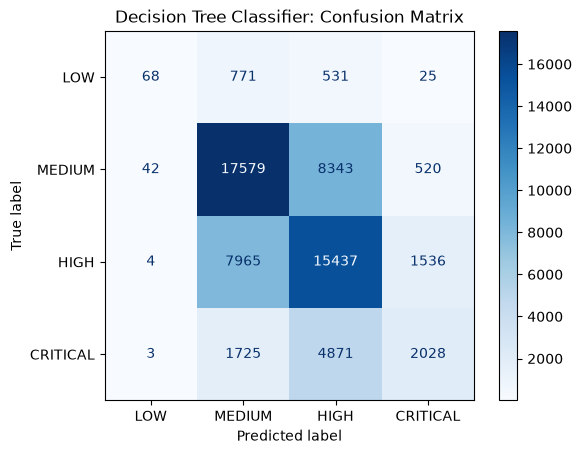

In [12]:
clf_tree = DecisionTreeClassifier(max_depth=15, random_state=42).fit(X_train_clf, y_train_clf)
y_pred_clf = clf_tree.predict(X_test_clf)
labels = ['LOW', 'MEDIUM', 'HIGH', 'CRITICAL']

acc_dt = accuracy_score(y_test_clf, y_pred_clf)
f1_dt = f1_score(y_test_clf, y_pred_clf, average='macro')
print(classification_report(y_test_clf, y_pred_clf, labels=labels, digits=3, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test_clf, y_pred_clf, labels=labels, cmap='Blues', values_format='d')
plt.title("Decision Tree Classifier: Confusion Matrix")
plt.show()

The tree is 57.1% accurate, 14 points above the 43% baseline, with a macro-F1 of 0.41. MEDIUM (F1 0.65) and HIGH (0.57) are predicted best. CRITICAL is found only 24% of the time, mostly mistaken for HIGH, and LOW only 5% of the time, because it is just 2% of the data. The confusion matrix shows most errors fall between neighboring levels.

**Visualizing the splits and feature importances:** we draw the top 3 levels of the tree and the 10 most important attributes. Each box shows the share of CVEs in each class, in the order CRITICAL, HIGH, LOW, MEDIUM.

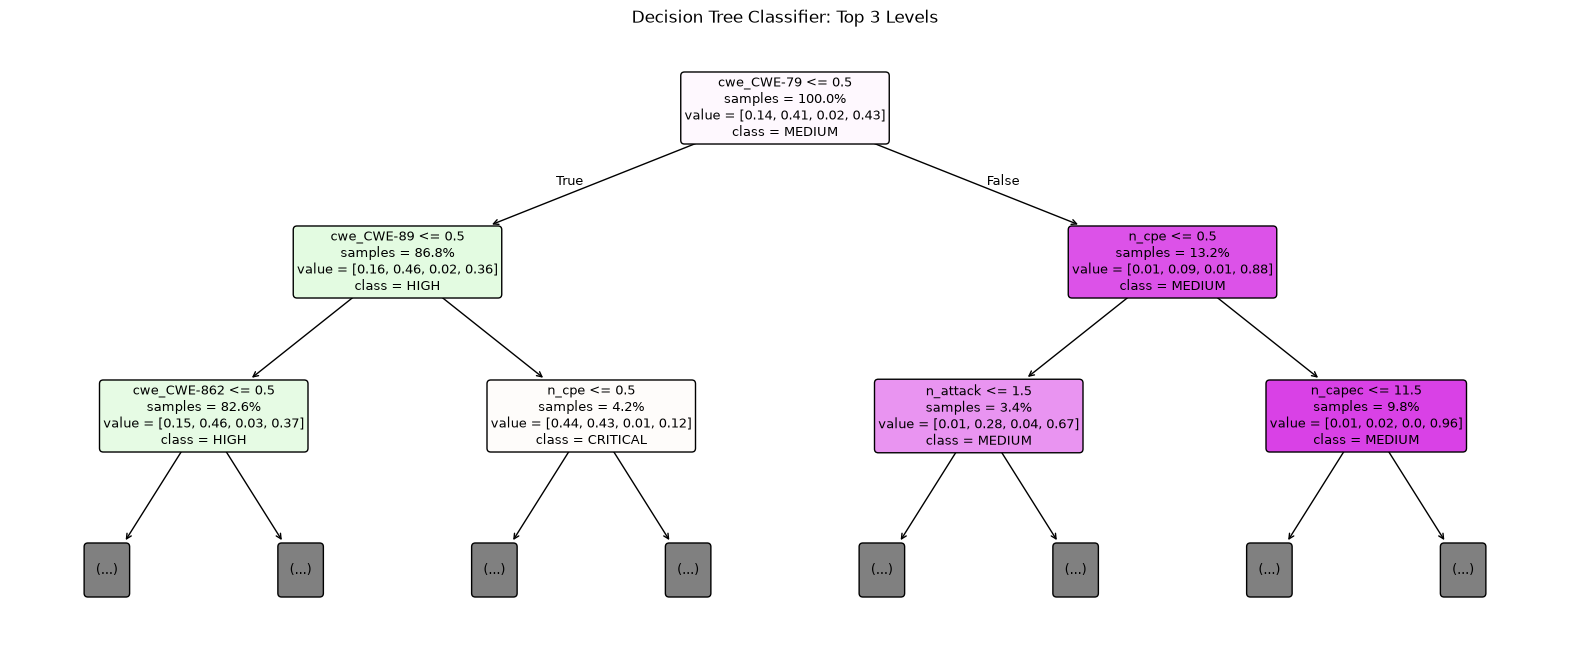

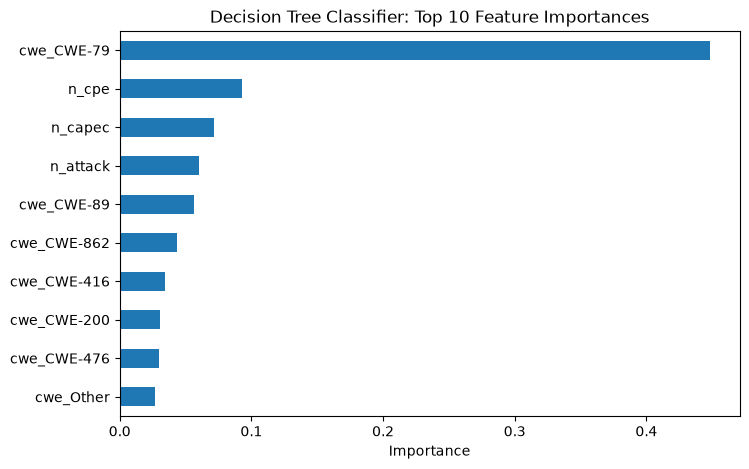

cwe_CWE-79     0.4485
n_cpe          0.0929
n_capec        0.0715
n_attack       0.0601
cwe_CWE-89     0.0561
cwe_CWE-862    0.0432
cwe_CWE-416    0.0341
cwe_CWE-200    0.0305
cwe_CWE-476    0.0297
cwe_Other      0.0267
dtype: float64


In [13]:
# Top 3 levels of the tree
plt.figure(figsize=(20, 8))
plot_tree(clf_tree, max_depth=2, feature_names=list(X_clf.columns), class_names=list(clf_tree.classes_),
          filled=True, rounded=True, fontsize=9, impurity=False, proportion=True, precision=2)
plt.title("Decision Tree Classifier: Top 3 Levels")
plt.show()

# Top 10 feature importances
clf_imp = pd.Series(clf_tree.feature_importances_, index=X_clf.columns).sort_values(ascending=False)
clf_imp.head(10).sort_values().plot(kind='barh', figsize=(8, 5))
plt.title("Decision Tree Classifier: Top 10 Feature Importances")
plt.xlabel("Importance")
plt.show()

print(clf_imp.head(10).round(4))

The first question is whether the CVE is CWE-79 (cross-site scripting). 88% of those CVEs are MEDIUM, so this one split explains most of what the tree learns (importance 0.45). On the other side, the tree checks for CWE-89 (SQL injection), and SQL injection CVEs with no listed product are mostly CRITICAL (44%).

After CWE-79, the most important attributes are the graph counts n_cpe (0.09), n_capec (0.07) and n_attack (0.06), followed by other common CWEs such as CWE-89, CWE-862 (missing authorization) and CWE-416 (use after free). The weakness type drives the predictions, and the graph counts add detail.

#### Report:

| Model | Attributes | Test accuracy | Test macro-F1 |
|---|---|---|---|
| Always guess MEDIUM | none | 43.1% | – |
| Naive Bayes (Progress Report 4) | description text | 63.8% | 0.49 |
| **Decision tree, max_depth=15** | **graph counts + top 20 CWEs** | **57.1%** | **0.41** |

The decision tree beats the baseline by 14 points using only the CWE and graph counts, but it is below Naive Bayes on the description text. The tree is easy to read: XSS CVEs are almost always MEDIUM, and SQL injection leans CRITICAL. It mostly fails on the rare LOW and CRITICAL levels.

### Task 3: Random Forest (Ensemble Learning)

A Random Forest trains many decision trees (here 100) and combines them: it averages their predictions for regression and takes a vote for classification. Each tree is trained on a **bootstrap sample**, a random draw of the training rows with replacement, and looks at a random subset of the attributes at each split. Because the trees make different mistakes, combining them usually reduces overfitting. We apply a forest to both tasks above, with the same attributes and max_depth as the single trees.

**Random Forest Regressor:** we predict base_score from the six Task 1 attributes with max_depth=10 and compare it with the final decision tree.

In [14]:
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier

rf_reg = RandomForestRegressor(n_estimators=100, max_depth=10, n_jobs=-1, random_state=42)
rf_reg.fit(X_train_dt, y_train_dt)
y_pred_rf = rf_reg.predict(X_test_dt)

reg_compare = pd.DataFrame({
    'Decision tree': [r2_score(y_train_dt, best_tree.predict(X_train_dt)), r2_dt, rmse_dt, mae_dt],
    'Random forest': [r2_score(y_train_dt, rf_reg.predict(X_train_dt)), r2_score(y_test_dt, y_pred_rf),
                      np.sqrt(mean_squared_error(y_test_dt, y_pred_rf)), mean_absolute_error(y_test_dt, y_pred_rf)],
}, index=['train R²', 'test R²', 'test RMSE', 'test MAE'])
display(reg_compare.round(4))

# Feature importances side by side
reg_imp = pd.DataFrame({'Decision tree': best_tree.feature_importances_,
                        'Random forest': rf_reg.feature_importances_}, index=features_dt)
display(reg_imp.round(4))

,Decision tree,Random forest
train R²,0.9996,0.9996
test R²,0.9995,0.9995
test RMSE,0.0379,0.0372
test MAE,0.0072,0.0072


,Decision tree,Random forest
exploitability_score,0.2887,0.2869
impact_score,0.7111,0.7130
n_cwe,0.0000,0.0000
n_cpe,0.0000,0.0000
n_capec,0.0001,0.0001
n_attack,0.0000,0.0000


The forest and the single tree are practically identical: test R² is 0.9995 for both, RMSE drops only from 0.0379 to 0.0372, and MAE is the same. The importances also match (impact_score 0.71, exploitability_score 0.29, graph counts about 0). The single tree already captures the CVSS formula and does not overfit, so there is nothing left for averaging to fix.

**Random Forest Classifier:** we predict severity from the 25 Task 2 attributes with max_depth=15 and compare it with the decision tree classifier.

              precision    recall  f1-score   support

         LOW      0.644     0.048     0.089      1395
      MEDIUM      0.634     0.659     0.646     26484
        HIGH      0.524     0.646     0.579     24942
    CRITICAL      0.521     0.182     0.270      8627

    accuracy                          0.573     61448
   macro avg      0.581     0.384     0.396     61448
weighted avg      0.573     0.573     0.553     61448



,Decision tree,Random forest
train accuracy,0.580,0.585
test accuracy,0.571,0.573
test macro-F1,0.406,0.396


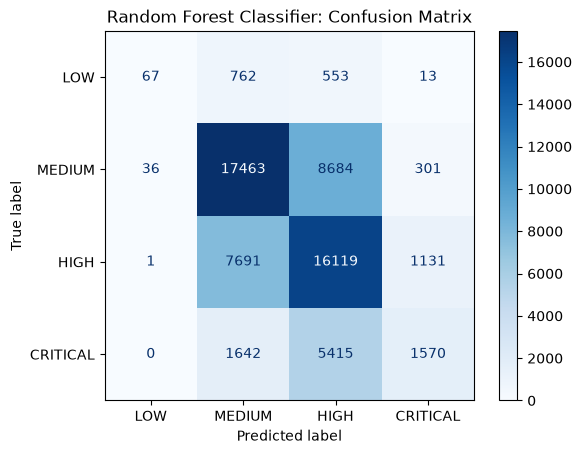

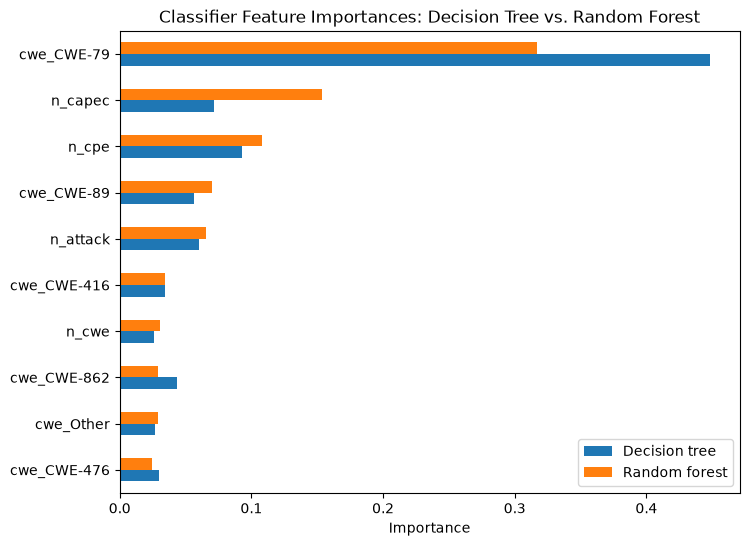

             Decision tree  Random forest
cwe_CWE-79          0.4485         0.3168
n_capec             0.0715         0.1535
n_cpe               0.0929         0.1084
cwe_CWE-89          0.0561         0.0699
n_attack            0.0601         0.0654
cwe_CWE-416         0.0341         0.0343
n_cwe               0.0257         0.0304
cwe_CWE-862         0.0432         0.0291
cwe_Other           0.0267         0.0290
cwe_CWE-476         0.0297         0.0244


In [15]:
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=15, n_jobs=-1, random_state=42)
rf_clf.fit(X_train_clf, y_train_clf)
y_pred_rfc = rf_clf.predict(X_test_clf)

print(classification_report(y_test_clf, y_pred_rfc, labels=labels, digits=3, zero_division=0))

clf_compare = pd.DataFrame({
    'Decision tree': [accuracy_score(y_train_clf, clf_tree.predict(X_train_clf)), acc_dt, f1_dt],
    'Random forest': [accuracy_score(y_train_clf, rf_clf.predict(X_train_clf)),
                      accuracy_score(y_test_clf, y_pred_rfc), f1_score(y_test_clf, y_pred_rfc, average='macro')],
}, index=['train accuracy', 'test accuracy', 'test macro-F1'])
display(clf_compare.round(3))

ConfusionMatrixDisplay.from_predictions(y_test_clf, y_pred_rfc, labels=labels, cmap='Blues', values_format='d')
plt.title("Random Forest Classifier: Confusion Matrix")
plt.show()

# Top 10 feature importances, tree vs. forest
clf_imp_both = pd.DataFrame({'Decision tree': clf_tree.feature_importances_,
                             'Random forest': rf_clf.feature_importances_}, index=X_clf.columns)
top10 = clf_imp_both.sort_values('Random forest', ascending=False).head(10)
top10.sort_values('Random forest').plot(kind='barh', figsize=(8, 6))
plt.title("Classifier Feature Importances: Decision Tree vs. Random Forest")
plt.xlabel("Importance")
plt.show()

print(top10.round(4))

The forest reaches 57.3% test accuracy, only 0.2 points above the single tree, and its macro-F1 is slightly lower (0.40 vs. 0.41), because it predicts CRITICAL less often (recall 18% vs. 24%). The train-test gap is about 1 point for both, so neither overfits much.

The feature rankings are similar but the forest spreads importance more evenly. CWE-79 is still first, but drops from 0.45 to 0.32, while n_capec doubles from 0.07 to 0.15 and moves to second. The single tree puts most weight on its first split, whereas the forest's random attribute subsets force many trees to split on other attributes.

#### Report:

| Task | Model | Train | Test | Other test metrics |
|---|---|---|---|---|
| Regression | Decision tree (depth 10) | R² 0.9996 | R² 0.9995 | RMSE 0.0379, MAE 0.0072 |
| Regression | Random forest (100 trees) | R² 0.9996 | R² 0.9995 | RMSE 0.0372, MAE 0.0072 |
| Classification | Decision tree (depth 15) | Acc 58.0% | Acc 57.1% | Macro-F1 0.41 |
| Classification | Random forest (100 trees) | Acc 58.5% | Acc 57.3% | Macro-F1 0.40 |

The Random Forest does not meaningfully beat the single tree on either task. For regression, the tree is already nearly perfect. For classification, the limit is the information in the attributes, not overfitting, so averaging many trees does not help. The forest's feature rankings are more stable and give more credit to the graph counts.

### Conclusion

We built decision trees for both regression and classification and compared them with Random Forests.

- **Regression:** a decision tree with max_depth=10 predicts base_score from the two CVSS sub-scores with R² 0.9995, cutting the RMSE of linear regression by about 80%. It does not overfit at any depth, and the graph counts are almost never used.
- **Classification:** predicting severity before scoring, from only the CWE and graph counts, reaches 57.1% accuracy against a 43% baseline. CWE-79 (XSS → MEDIUM) is the strongest signal, and LOW and CRITICAL are hard to catch.
- **Single tree vs. Random Forest:** the forest matched the tree on both tasks (R² 0.9995 for both, 57.3% vs. 57.1% accuracy). It spread importance more evenly, giving more weight to the graph counts such as n_capec.

**Key takeaways:** a single tree is enough when the attributes fully determine the target, and a forest cannot add information that the attributes do not contain. To predict severity before scoring, we need richer inputs, such as the description text (63.8% with Naive Bayes) and the full knowledge-graph structure, which we will test with a GNN.